# 05 · ROI-embedding classifiers: `cell_type` and `domain`

Trains two simple **logistic regression** classifiers on the per-cell UNI2 embeddings
produced by `scripts/extract_cell_embeddings_roi.py`:

- **`cell_type`** classifier (Malignant / Stromal / Myeloid / Endothelial / Lymphoid / Epithelial / Pericytes)
- **`domain`** classifier (Tumor / Smooth muscle / Necrosis / Fallopian tube / Ovary)

**Split unit is `roi_id`, not cell.** `extract_cell_embeddings_roi.py`'s whole design
rationale is that adjacent cells' tiles overlap heavily, so a random *cell*-level
train/test split leaks train pixels into test tiles. Instead, whole ROIs are assigned to
train or test (never split within an ROI), and both tasks reuse **the same** ROI
assignment.

**Known limitation, not a bug:** the extraction script targeted 12 ROIs/domain but only
hit that for Tumor and Smooth muscle — Ovary (6), Fallopian tube (4), and especially
Necrosis (2 ROIs total) fell short because those tissue regions don't physically have
room for more non-overlapping 150um circles at the purity threshold used. With only 2
Necrosis ROIs, the best an "80/20" split can do is 1 ROI train / 1 ROI test (~50/50) —
this is called out explicitly below rather than silently reported as if it were 80/20.

Run under the **`lazyslide-env`** conda env (has sklearn 1.9, joblib, seaborn already).

In [ ]:
import itertools
from pathlib import Path

import anndata as ad
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, classification_report, confusion_matrix, roc_auc_score
from sklearn.preprocessing import StandardScaler

# absolute path: kernel cwd depends on how Jupyter was launched/connected, so a
# relative "../data" path is not reliable (e.g. VSCode "Existing Jupyter Server").
DATA_DIR = Path("/g/stegle/spiljak/projects/main_wsi_ood/data/ovca_roi_embeddings")
H5AD_PATH = DATA_DIR / "ovca_roi_cell_embeddings.h5ad"

EMBEDDING_KEY = "uni2"
TARGET_TEST_FRACTION = 0.20
CLASS_WEIGHT = "balanced"
MAX_ITER = 2000

## 1. Load embeddings + labels

In [2]:
adata = ad.read_h5ad(H5AD_PATH)
print(adata)
print()
print(f"embedding '{EMBEDDING_KEY}' shape: {adata.obsm[EMBEDDING_KEY].shape}")
print()
print("cell_type counts (incl. missing):")
print(adata.obs["cell_type"].value_counts(dropna=False))
print()
print("domain counts (incl. missing):")
print(adata.obs["domain"].value_counts(dropna=False))
print()
print(f"n ROIs: {adata.obs['roi_id'].nunique()}")
print("ROIs per roi_domain:")
print(adata.obs.drop_duplicates("roi_id")["roi_domain"].value_counts())

AnnData object with n_obs × n_vars = 17278 × 1
    obs: 'cell_id', 'cell_type', 'cell_type_minor', 'domain', 'roi_id', 'roi_domain', 'roi_purity', 'x_he', 'y_he', 'tile_id'
    obsm: 'uni2'

embedding 'uni2' shape: (17278, 1536)

cell_type counts (incl. missing):
cell_type
Malignant      9103
Stromal        5351
Epithelial     1142
Myeloid         646
Endothelial     582
Lymphoid        288
Pericytes       153
NaN              13
Name: count, dtype: int64

domain counts (incl. missing):
domain
Tumor             8017
NaN               3108
Smooth muscle     2803
Fallopian tube    1619
Necrosis          1218
Ovary              513
Name: count, dtype: int64

n ROIs: 36
ROIs per roi_domain:
roi_domain
Smooth muscle     12
Tumor             12
Ovary              6
Fallopian tube     4
Necrosis           2
Name: count, dtype: int64


## 2. ROI-level train/test split

For each `roi_domain` group independently, brute-force search over all subsets of its
ROIs (feasible since group sizes are tiny: 2, 4, 6, 12, 12) for the one whose **cell
count** fraction is closest to 20%, with at least one ROI on each side whenever the
group has >=2 ROIs. This is deterministic (no RNG needed) and reused identically for
both classifiers, so "train"/"test" mean the same physical slide regions in both.

In [3]:
def best_roi_split(roi_ids, roi_counts, target_frac):
    '''Return (train_ids, test_ids, achieved_test_frac) minimizing
    |test_frac - target_frac| over all non-trivial subsets of roi_ids assigned to test.'''
    roi_ids = sorted(roi_ids)
    total = sum(roi_counts[r] for r in roi_ids)
    n = len(roi_ids)
    best_score, best_test_ids = None, None
    for k in range(1, n):  # both sides non-empty
        for combo in itertools.combinations(roi_ids, k):
            test_cells = sum(roi_counts[r] for r in combo)
            score = abs(test_cells / total - target_frac)
            if best_score is None or score < best_score:
                best_score, best_test_ids = score, combo
    test_ids = set(best_test_ids)
    train_ids = [r for r in roi_ids if r not in test_ids]
    achieved_frac = sum(roi_counts[r] for r in test_ids) / total
    return train_ids, sorted(test_ids), achieved_frac


roi_cell_counts = adata.obs.groupby(["roi_domain", "roi_id"]).size()

split_assignment = {}  # roi_id -> "train" / "test"
summary_rows = []
for domain_name, grp in roi_cell_counts.groupby(level=0):
    roi_ids = grp.index.get_level_values("roi_id").tolist()
    counts = {rid: int(grp.loc[(domain_name, rid)]) for rid in roi_ids}
    train_ids, test_ids, achieved_frac = best_roi_split(roi_ids, counts, TARGET_TEST_FRACTION)
    for r in train_ids:
        split_assignment[r] = "train"
    for r in test_ids:
        split_assignment[r] = "test"
    summary_rows.append(
        {
            "roi_domain": domain_name,
            "n_rois": len(roi_ids),
            "n_train_rois": len(train_ids),
            "n_test_rois": len(test_ids),
            "n_cells": sum(counts.values()),
            "target_test_frac": TARGET_TEST_FRACTION,
            "achieved_test_frac": round(achieved_frac, 3),
        }
    )

split_summary = pd.DataFrame(summary_rows)
print(split_summary.to_string(index=False))
print(
    "\nNote: Necrosis has only 2 ROIs total, so its split is a forced ~50/50 "
    "(1 ROI train / 1 ROI test) -- not a real 80/20, flagged here rather than hidden."
)

adata.obs["split"] = adata.obs["roi_id"].map(split_assignment)
assert adata.obs["split"].isin(["train", "test"]).all()

    roi_domain  n_rois  n_train_rois  n_test_rois  n_cells  target_test_frac  achieved_test_frac
Fallopian tube       4             3            1     2592               0.2               0.190
      Necrosis       2             1            1     1490               0.2               0.489
         Ovary       6             4            2      654               0.2               0.203
 Smooth muscle      12             9            3     4348               0.2               0.200
         Tumor      12            10            2     8194               0.2               0.200

Note: Necrosis has only 2 ROIs total, so its split is a forced ~50/50 (1 ROI train / 1 ROI test) -- not a real 80/20, flagged here rather than hidden.


Sanity check: per-class cell counts in each split, for both label columns. A class with 0 in either split cannot be trained on and/or cannot be evaluated for that task.

In [4]:
for col in ["cell_type", "domain"]:
    print(f"=== {col} x split ===")
    print(pd.crosstab(adata.obs[col], adata.obs["split"], dropna=False))
    print()

=== cell_type x split ===
split        test  train
cell_type               
NaN             6      7
Endothelial   133    449
Epithelial    176    966
Lymphoid       79    209
Malignant    2269   6834
Myeloid       187    459
Pericytes      10    143
Stromal      1002   4349

=== domain x split ===
split           test  train
domain                     
NaN              670   2438
Fallopian tube   303   1316
Necrosis         698    520
Ovary            117    396
Smooth muscle    587   2216
Tumor           1487   6530



## 3. Modeling helper

Shared logic for both tasks:

1. Drop rows with a missing label for *this* task only (13 for `cell_type`, ~3.1k for `domain`)
   — the ROI split itself doesn't change, only which rows participate.
2. `StandardScaler` fit on train only, applied to train+test.
3. `LogisticRegression(class_weight="balanced")` — both label sets are imbalanced
   (e.g. Pericytes vs Malignant, Ovary vs Tumor), so unweighted accuracy would be
   dominated by the majority class.
4. Save the fitted `(scaler, clf)` and the full per-cell predictions (train **and**
   test, with per-class probabilities) to disk, so no refit is needed later just to
   recompute a metric.
5. Report on test only: classification report, balanced accuracy, macro AUROC (OvR),
   confusion matrix (counts + row-normalized), and a per-domain accuracy breakdown.

In [5]:
def fit_eval_task(adata, target_col, out_dir, embedding_key=EMBEDDING_KEY):
    obs = adata.obs
    mask = obs[target_col].notna().to_numpy()
    X = np.asarray(adata.obsm[embedding_key])[mask]
    y = obs.loc[mask, target_col].astype(str).to_numpy()
    split = obs.loc[mask, "split"].to_numpy()
    cell_id = obs.loc[mask, "cell_id"].to_numpy()
    roi_id = obs.loc[mask, "roi_id"].to_numpy()
    domain = obs.loc[mask, "domain"].astype(str).to_numpy()

    train_m, test_m = split == "train", split == "test"
    print(
        f"[{target_col}] dropped {int((~mask).sum())} rows with missing label "
        f"-> {mask.sum()} remain (train={train_m.sum()}, test={test_m.sum()})"
    )

    scaler = StandardScaler().fit(X[train_m])
    X_scaled = scaler.transform(X)

    clf = LogisticRegression(class_weight=CLASS_WEIGHT, max_iter=MAX_ITER, n_jobs=-1)
    clf.fit(X_scaled[train_m], y[train_m])

    proba_all = clf.predict_proba(X_scaled)
    pred_all = clf.classes_[np.argmax(proba_all, axis=1)]

    # --- persist raw per-cell outputs (train + test) ---
    pred_df = pd.DataFrame(
        {
            "cell_id": cell_id,
            "roi_id": roi_id,
            "split": split,
            f"true_{target_col}": y,
            f"pred_{target_col}": pred_all,
        }
    )
    for i, c in enumerate(clf.classes_):
        pred_df[f"proba_{c}"] = proba_all[:, i]
    pred_path = out_dir / f"{target_col}_predictions.csv"
    pred_df.to_csv(pred_path, index=False)

    model_path = out_dir / f"{target_col}_logreg.joblib"
    joblib.dump({"scaler": scaler, "clf": clf, "classes_": clf.classes_}, model_path)
    print(f"[{target_col}] saved model -> {model_path}")
    print(f"[{target_col}] saved predictions -> {pred_path}")

    # --- eval on test only ---
    y_test, pred_test, proba_test = y[test_m], pred_all[test_m], proba_all[test_m]
    labels_sorted = sorted(clf.classes_)

    print(f"\n=== {target_col}: classification report (test) ===")
    print(classification_report(y_test, pred_test, labels=labels_sorted, zero_division=0))

    bal_acc = balanced_accuracy_score(y_test, pred_test)
    print(f"balanced_accuracy = {bal_acc:.4f}")

    try:
        auroc = roc_auc_score(y_test, proba_test, multi_class="ovr", average="macro", labels=clf.classes_)
        print(f"macro AUROC (OvR) = {auroc:.4f}")
    except ValueError as e:
        auroc = np.nan
        print(f"macro AUROC unavailable: {e}")

    cm = confusion_matrix(y_test, pred_test, labels=labels_sorted)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    cm_df = pd.DataFrame(cm, index=labels_sorted, columns=labels_sorted)
    cm_norm_df = pd.DataFrame(cm_norm, index=labels_sorted, columns=labels_sorted)

    n = len(labels_sorted)
    fig, axes = plt.subplots(1, 2, figsize=(0.9 * n + 5, 0.9 * n + 2))
    for ax, data, title, fmt in [
        (axes[0], cm_df, "counts", "d"),
        (axes[1], cm_norm_df, "row-normalized (recall)", ".2f"),
    ]:
        sns.heatmap(data, annot=True, fmt=fmt, cmap="Blues", ax=ax, cbar=False)
        ax.set_title(f"{target_col}: {title}")
        ax.set_xlabel("predicted")
        ax.set_ylabel("true")
    plt.tight_layout()
    plt.show()

    dom_test = domain[test_m]
    breakdown = pd.DataFrame({"domain": dom_test, "correct": (y_test == pred_test)})
    per_domain = breakdown.groupby("domain").agg(n=("correct", "size"), accuracy=("correct", "mean"))
    print(f"\n=== {target_col}: per-domain test accuracy ===")
    print(per_domain)

    return {
        "model_path": model_path,
        "pred_path": pred_path,
        "balanced_accuracy": bal_acc,
        "macro_auroc": auroc,
        "confusion_matrix": cm_df,
        "per_domain": per_domain,
    }

## 4. `cell_type` classifier

[cell_type] dropped 13 rows with missing label -> 17265 remain (train=13409, test=3856)


/g/stegle/spiljak/programs/miniforge3/envs/lazyslide-env/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


[cell_type] saved model -> /g/stegle/spiljak/projects/main_wsi_ood/data/ovca_roi_embeddings/cell_type_logreg.joblib
[cell_type] saved predictions -> /g/stegle/spiljak/projects/main_wsi_ood/data/ovca_roi_embeddings/cell_type_predictions.csv

=== cell_type: classification report (test) ===
              precision    recall  f1-score   support

 Endothelial       0.06      0.14      0.08       133
  Epithelial       0.42      0.51      0.46       176
    Lymphoid       0.03      0.25      0.06        79
   Malignant       0.82      0.54      0.65      2269
     Myeloid       0.06      0.14      0.09       187
   Pericytes       0.08      0.10      0.09        10
     Stromal       0.81      0.65      0.73      1002

    accuracy                           0.53      3856
   macro avg       0.33      0.33      0.31      3856
weighted avg       0.72      0.53      0.60      3856

balanced_accuracy = 0.3336
macro AUROC (OvR) = 0.7585


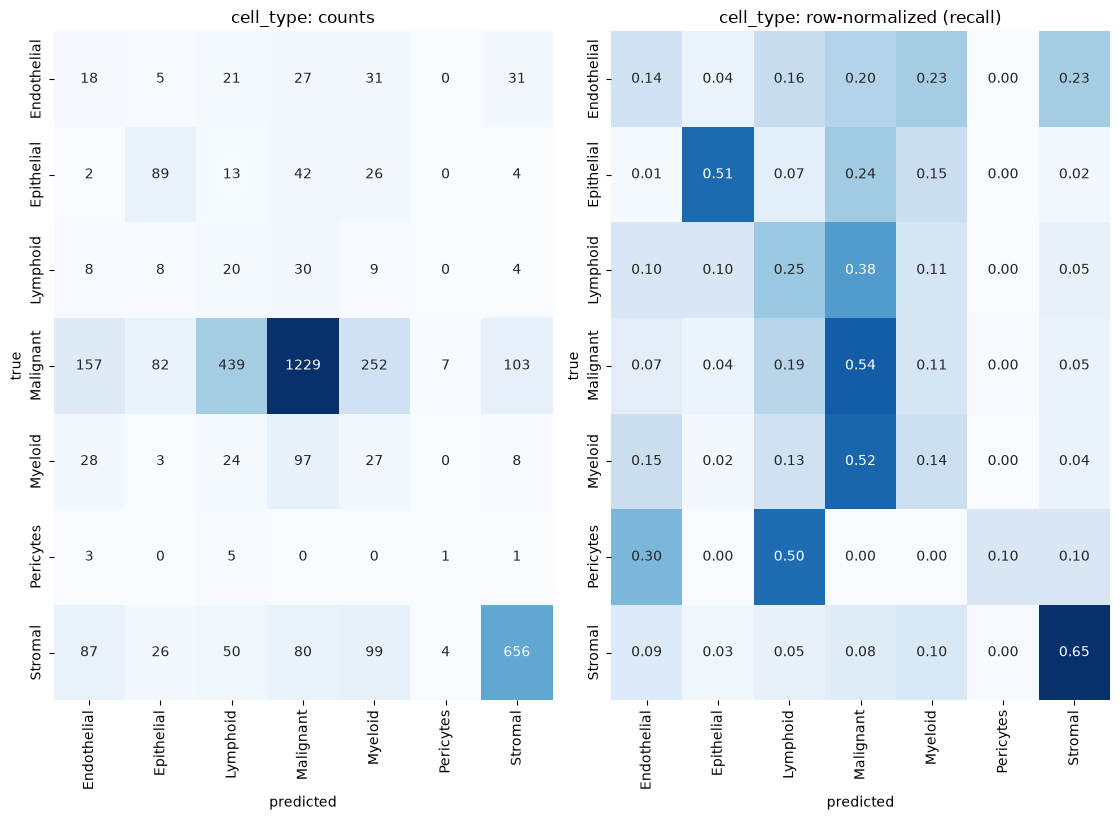


=== cell_type: per-domain test accuracy ===
                   n  accuracy
domain                        
Fallopian tube   303  0.211221
Necrosis         698  0.393983
Ovary            117  0.427350
Smooth muscle    587  0.822828
Tumor           1487  0.591796


In [6]:
cell_type_results = fit_eval_task(adata, "cell_type", DATA_DIR)

## 5. `domain` classifier

[domain] dropped 3108 rows with missing label -> 14170 remain (train=10978, test=3192)


/g/stegle/spiljak/programs/miniforge3/envs/lazyslide-env/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


[domain] saved model -> /g/stegle/spiljak/projects/main_wsi_ood/data/ovca_roi_embeddings/domain_logreg.joblib
[domain] saved predictions -> /g/stegle/spiljak/projects/main_wsi_ood/data/ovca_roi_embeddings/domain_predictions.csv

=== domain: classification report (test) ===
                precision    recall  f1-score   support

Fallopian tube       1.00      0.93      0.96       303
      Necrosis       0.94      0.95      0.94       698
         Ovary       1.00      1.00      1.00       117
 Smooth muscle       0.96      1.00      0.98       587
         Tumor       0.98      0.97      0.97      1487

      accuracy                           0.97      3192
     macro avg       0.98      0.97      0.97      3192
  weighted avg       0.97      0.97      0.97      3192

balanced_accuracy = 0.9701
macro AUROC (OvR) = 0.9986


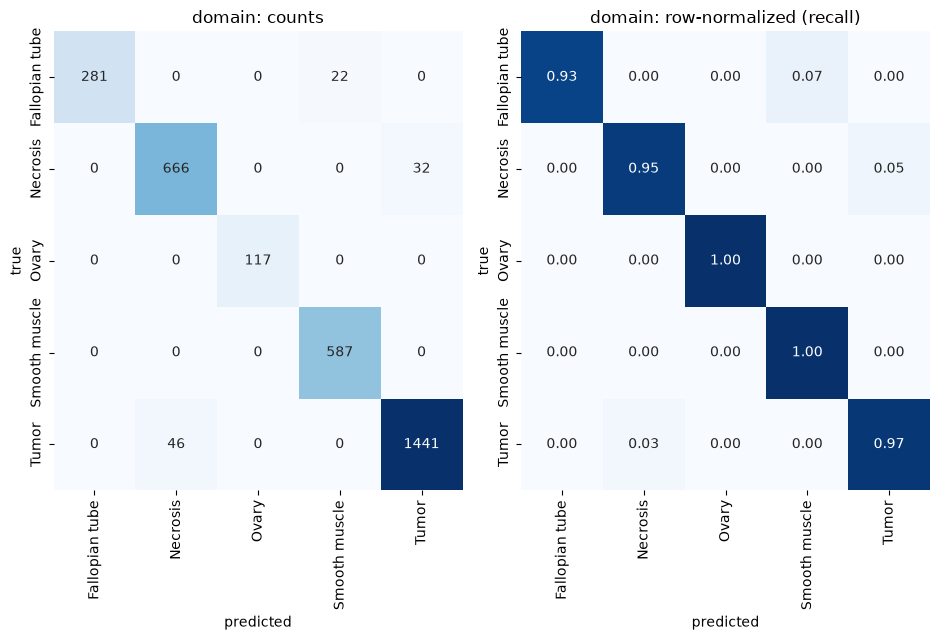


=== domain: per-domain test accuracy ===
                   n  accuracy
domain                        
Fallopian tube   303  0.927393
Necrosis         698  0.954155
Ovary            117  1.000000
Smooth muscle    587  1.000000
Tumor           1487  0.969065


In [7]:
domain_results = fit_eval_task(adata, "domain", DATA_DIR)

## 6. Summary & caveats

- `domain` classes are guaranteed present in both splits (the split is stratified by
  `roi_domain` itself); `cell_type` classes are **not** explicitly stratified, so check
  the per-class train/test counts printed in step 2 before trusting a rare class's
  test metrics (e.g. Pericytes only ever occurs in Tumor-domain ROIs).
- Necrosis's train/test split is a forced ~50/50 (only 2 ROIs exist) and Fallopian
  tube's is based on only 4 ROIs — treat those domains' test numbers as high-variance,
  not a reliable estimate of generalization.
- Trained models: `cell_type_logreg.joblib`, `domain_logreg.joblib`.
- Raw per-cell predictions (train + test, full probability vectors):
  `cell_type_predictions.csv`, `domain_predictions.csv`.